<a href="https://colab.research.google.com/github/gozdekorkut/double-descent-reproduction/blob/main/notebooks/01_rff_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Double descent with Random Fourier Features on MNIST

Reproduces **Figure 2** of Belkin, Hsu, Ma & Mandal (2019), *Reconciling modern machine-learning practice and the classical bias–variance trade-off*, PNAS.

**What this notebook does**

1. Takes a random subset of `n` MNIST training images (paper: n = 10,000).
2. For each number of features `N`, builds the random Fourier feature map
   $\phi(x) = \sqrt{2/N}\,\cos(V^\top x + b)$ with $v_k \sim \mathcal N(0, \sigma^{-2} I)$, $b_k \sim U[0, 2\pi]$.
3. Fits the output weights $A \in \mathbb R^{N \times 10}$ by **minimum-norm least squares** (the pseudo-inverse), with no regularisation.
4. Records train/test zero-one error, train/test squared loss and $\|A\|_F$.
5. Also fits the **kernel limit** $h_{n,\infty}$ (Gaussian kernel, $N \to \infty$), the horizontal line in the paper's figure.
6. Repeats for several seeds and plots mean ± std.

**What we expect:** test error peaks at the interpolation threshold **N = n**, the norm peaks there too, and for N ≫ n the test error drops below the best N < n model.

Run on a GPU runtime (*Runtime → Change runtime type → T4 GPU*). Results are appended to a CSV on Google Drive after every model, so if the session disconnects, re-run all cells and it continues where it stopped.

## 1. Settings
Change only this cell. Start with `PILOT = True` (takes about 1 minute) to check everything works, then set it to `False` for the real run.

In [17]:
PILOT = False          # True: small, fast check. False: the real experiment.

if PILOT:
    N_TRAIN = 1_000
    SEEDS = [0]
else:
    N_TRAIN = 10_000  # paper: n = 10^4
    SEEDS = [0, 1, 2]  # course requires >= 3 seeds

SIGMA = 5.0           # kernel bandwidth; paper Appendix C.1 uses sigma = 5 for MNIST
# Numbers of features, as multiples of n. Dense around 1.0 because the peak is narrow.
N_FRACTIONS = [0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 1.0, 1.05, 1.1, 1.2, 1.5, 2, 3, 4, 6]
CHUNK = 4096          # features processed at a time (keeps GPU memory low)

DRIVE_DIR = "/content/drive/MyDrive/double-descent"
TAG = "pilot" if PILOT else "full"
RESULTS_CSV = f"{DRIVE_DIR}/results/rff_mnist_{TAG}.csv"
KERNEL_CSV  = f"{DRIVE_DIR}/results/rff_kernel_mnist_{TAG}.csv"

## 2. Setup: Drive, imports, device

In [18]:
import os, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass  # not on Colab

for sub in ["results", "checkpoints", "figures"]:
    os.makedirs(f"{DRIVE_DIR}/{sub}", exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float64   # float64 is essential: near N = n the problem is badly conditioned
print("device:", DEVICE, "| torch", torch.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | torch 2.14.1+cu130


## 3. Shared helpers (identical in every notebook)

- `load_mnist_subset`: pixels scaled to [0, 1], images flattened to 784 numbers, labels one-hot encoded (paper Appendix B). The training subset is drawn uniformly without replacement using the seed; the test set is the full 10,000 MNIST test images.
- `append_result` / `done_keys`: write one CSV row per finished model, and skip models already in the CSV when the notebook is re-run.

In [19]:
import torchvision

def load_mnist_subset(n_train, seed, root="/content/data"):
    train = torchvision.datasets.MNIST(root, train=True, download=True)
    test = torchvision.datasets.MNIST(root, train=False, download=True)
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(train.targets), generator=g)[:n_train]
    def prep(images, labels):
        X = images.reshape(len(images), -1).to(DTYPE) / 255.0          # (m, 784), values in [0, 1]
        Y = torch.nn.functional.one_hot(labels, 10).to(DTYPE)          # (m, 10)
        return X.to(DEVICE), Y.to(DEVICE)
    Xtr, Ytr = prep(train.data[idx], train.targets[idx])
    Xte, Yte = prep(test.data, test.targets)
    return Xtr, Ytr, Xte, Yte

def append_result(path, row):
    pd.DataFrame([row]).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

def done_keys(path, cols):
    if not os.path.exists(path):
        return set()
    return set(map(tuple, pd.read_csv(path)[cols].values.tolist()))

def zero_one(P, Y):   # % of points where the predicted class (largest output) is wrong
    return 100.0 * (P.argmax(1) != Y.argmax(1)).double().mean().item()

def sq_loss(P, Y):    # squared loss summed over the 10 outputs, averaged over points
    return ((P - Y) ** 2).sum(1).mean().item()

## 4. The method

**Features.** Each column $v_k$ of $V \in \mathbb R^{784 \times N}$ is drawn from $\mathcal N(0, \sigma^{-2} I)$ and $b_k \sim U[0, 2\pi]$. The feature matrix of a batch $X \in \mathbb R^{m \times 784}$ is
$\Phi = \sqrt{2/N}\,\cos(XV + \mathbf 1 b^\top) \in \mathbb R^{m \times N}$.
With this scaling, $\Phi\Phi^\top \to K$ (the Gaussian kernel matrix) as $N \to \infty$, so $\|A\|_F$ is comparable to the kernel solution's RKHS norm.

**Minimum-norm least squares.** We want $A = \Phi^+ Y$ (the pseudo-inverse), which is the ordinary least-squares solution when $N < n$ and the smallest-norm exact fit when $N \ge n$. We compute it through the eigendecomposition of the smaller Gram matrix:

- $N \ge n$: $G = \Phi\Phi^\top \in \mathbb R^{n\times n} = U\Lambda U^\top$, so $A = \Phi^\top U \Lambda^{-1} U^\top Y$.
- $N < n$: $G = \Phi^\top\Phi \in \mathbb R^{N\times N} = W\Lambda W^\top$, so $A = W \Lambda^{-1} W^\top \Phi^\top Y$.

Eigenvalues below machine precision are treated as zero (this is exactly what a pseudo-inverse does). We add **no** ridge regularisation, because that would shrink the peak we want to see.

For $N \ge n$ we never store the whole $n \times N$ matrix $\Phi$ (10,000 × 60,000 in float64 = 4.8 GB); we build $G$ and the predictions chunk by chunk from $V$.

In [20]:
def features(X, V, b, N):
    # X: (m, d), V: (d, c), b: (c,)  ->  (m, c); N is the total number of features (for the scaling)
    return np.sqrt(2.0 / N) * torch.cos(X @ V + b)

def pinv_apply(G, R):
    # Returns G^+ R for a symmetric positive semi-definite G, via eigendecomposition.
    lam, U = torch.linalg.eigh(G)
    tol = lam.max() * G.shape[0] * torch.finfo(G.dtype).eps
    inv = torch.where(lam > tol, 1.0 / lam, torch.zeros_like(lam))
    return U @ (inv[:, None] * (U.T @ R))

def fit_rff(Xtr, Ytr, Xte, Yte, N, seed):
    n, d = Xtr.shape
    g = torch.Generator().manual_seed(1000 + seed)              # feature seed (separate from the data seed)
    V = (torch.randn(d, N, generator=g, dtype=DTYPE) / SIGMA).to(DEVICE)
    b = (2 * np.pi * torch.rand(N, generator=g, dtype=DTYPE)).to(DEVICE)
    chunks = [slice(i, min(i + CHUNK, N)) for i in range(0, N, CHUNK)]

    if N < n:
        Phi = features(Xtr, V, b, N)                               # (n, N)
        A = pinv_apply(Phi.T @ Phi, Phi.T @ Ytr)                   # (N, 10)
        Ptr = Phi @ A
        Pte = features(Xte, V, b, N) @ A
        norm = torch.linalg.norm(A).item()
    else:
        G = torch.zeros(n, n, dtype=DTYPE, device=DEVICE)
        for c in chunks:                                           # G = Phi Phi^T, built chunk by chunk
            Pc = features(Xtr, V[:, c], b[c], N)
            G += Pc @ Pc.T
        alpha = pinv_apply(G, Ytr)                                 # (n, 10), A = Phi^T alpha
        Ptr = torch.zeros_like(Ytr); Pte = torch.zeros_like(Yte); sq = 0.0
        for c in chunks:
            Pc = features(Xtr, V[:, c], b[c], N)
            Ac = Pc.T @ alpha                                      # rows c of A
            Ptr += Pc @ Ac
            Pte += features(Xte, V[:, c], b[c], N) @ Ac
            sq += (Ac ** 2).sum().item()
        norm = sq ** 0.5

    return dict(train_err=zero_one(Ptr, Ytr), test_err=zero_one(Pte, Yte),
                train_mse=sq_loss(Ptr, Ytr), test_mse=sq_loss(Pte, Yte), norm=norm)

**Kernel limit** $h_{n,\infty}$. As $N \to \infty$ the features give the Gaussian kernel
$k(x, x') = \exp(-\|x - x'\|^2 / 2\sigma^2)$. The minimum-norm interpolant is $h(x) = \sum_i \alpha_i k(x, x_i)$ with $\alpha = K^+ Y$, and its RKHS norm is $\sqrt{\operatorname{tr}(\alpha^\top K \alpha)}$.

In [21]:
def gauss_kernel(X1, X2):
    return torch.exp(-torch.cdist(X1, X2) ** 2 / (2 * SIGMA ** 2))

def fit_kernel(Xtr, Ytr, Xte, Yte):
    K = gauss_kernel(Xtr, Xtr)
    alpha = pinv_apply(K, Ytr)
    Ptr = K @ alpha
    Pte = gauss_kernel(Xte, Xtr) @ alpha
    norm = torch.sqrt(torch.trace(alpha.T @ K @ alpha)).item()
    return dict(train_err=zero_one(Ptr, Ytr), test_err=zero_one(Pte, Yte),
                train_mse=sq_loss(Ptr, Ytr), test_mse=sq_loss(Pte, Yte), norm=norm)

## 5. Run the experiment
Each finished model is saved immediately. Already finished `(seed, N)` pairs are skipped.

In [22]:
N_LIST = sorted({int(round(f * N_TRAIN)) for f in N_FRACTIONS})
done = done_keys(RESULTS_CSV, ["seed", "N"])
print(f"n = {N_TRAIN}, seeds = {SEEDS}, N values = {N_LIST}")

for seed in SEEDS:
    Xtr, Ytr, Xte, Yte = load_mnist_subset(N_TRAIN, seed)
    for N in N_LIST:
        if (seed, N) in done:
            continue
        t0 = time.time()
        r = fit_rff(Xtr, Ytr, Xte, Yte, N, seed)
        row = dict(seed=seed, n=N_TRAIN, N=N, **r, seconds=round(time.time() - t0, 1))
        append_result(RESULTS_CSV, row)
        print(f"seed {seed}  N={N:6d}  train {r['train_err']:5.1f}%  test {r['test_err']:5.1f}%  "
              f"norm {r['norm']:10.2f}  ({row['seconds']} s)")
    if (seed,) not in done_keys(KERNEL_CSV, ["seed"]):
        r = fit_kernel(Xtr, Ytr, Xte, Yte)
        append_result(KERNEL_CSV, dict(seed=seed, n=N_TRAIN, **r))
        print(f"seed {seed}  kernel     test {r['test_err']:5.1f}%  norm {r['norm']:.2f}")
    del Xtr, Ytr, Xte, Yte
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

n = 10000, seeds = [0, 1, 2], N values = [200, 500, 1000, 2000, 4000, 6000, 8000, 9000, 9500, 10000, 10500, 11000, 12000, 15000, 20000, 30000, 40000, 60000]
seed 0  N=   200  train  15.5%  test  15.9%  norm       7.36  (0.1 s)
seed 0  N=   500  train   7.9%  test   9.2%  norm      11.68  (0.2 s)
seed 1  N=   200  train  15.6%  test  15.7%  norm       7.30  (0.1 s)
seed 1  N=   500  train   7.7%  test  10.1%  norm      11.51  (0.1 s)
seed 2  N=   200  train  15.8%  test  16.2%  norm       7.32  (0.1 s)
seed 2  N=   500  train   7.4%  test   9.7%  norm      11.53  (0.1 s)


## 6. Results table (mean ± std over seeds)

In [23]:
df = pd.read_csv(RESULTS_CSV)
ker = pd.read_csv(KERNEL_CSV)
summary = df.groupby("N")[["train_err", "test_err", "test_mse", "norm"]].agg(["mean", "std"]).round(2)
display(summary)
print("Kernel limit:", ker[["test_err", "test_mse", "norm"]].agg(["mean", "std"]).round(2).to_dict())

train_err       test_err       test_mse            norm        
           mean   std     mean   std     mean    std     mean     std
N                                                                    
200       15.62  0.18    15.95  0.22     0.43   0.00     7.33    0.03
500        7.68  0.24     9.66  0.42     0.32   0.00    11.57    0.09
1000       3.78  0.02     6.77  0.18     0.26   0.00    16.67    0.15
2000       1.27  0.02     5.48  0.26     0.23   0.00    25.55    0.24
4000       0.07  0.01     5.09  0.21     0.25   0.00    46.22    0.30
6000       0.01  0.01     6.04  0.28     0.33   0.01    75.05    0.34
8000       0.00  0.00    11.94  0.27     0.65   0.01   134.14    1.17
9000       0.00  0.00    23.38  0.41     1.28   0.02   210.09    1.83
9500       0.00  0.00    36.79  0.17     2.35   0.03   298.33    2.09
10000      0.00  0.00    83.62  1.09   209.56  65.42  2922.09  490.43
10500      0.00  0.00    32.93  1.06     2.02   0.06   290.12    4.62
11000      0.00  0.00    19.48  0.69     1.04   0.03   208.11    3.02
12000      0.00  0.00    10.04  0.23     0.56   0.01   152.13    1.06
15000      0.00  0.00     4.72  0.17     0.28   0.00   107.51    0.85
20000      0.00  0.00     3.58  0.14     0.18   0.00    87.98    1.10
30000      0.00  0.00     2.86  0.03     0.14   0.00    75.70    0.49
40000      0.00  0.00     2.78  0.02     0.12   0.00    71.12    0.62
60000      0.00  0.00     2.76  0.07     0.11   0.00    67.35    0.55

Kernel limit: {'test_err': {'mean': 2.52, 'std': 0.03}, 'test_mse': {'mean': 0.09, 'std': 0.0}, 'norm': {'mean': 61.23, 'std': 0.53}}


## 7. Figure 2 reproduction
Same layout as the paper: columns = zero-one loss and squared loss; rows = test risk (log scale), norm (log scale), train risk. Shaded band = ± 1 std over seeds; dotted line = interpolation threshold N = n; dashed line = kernel limit.

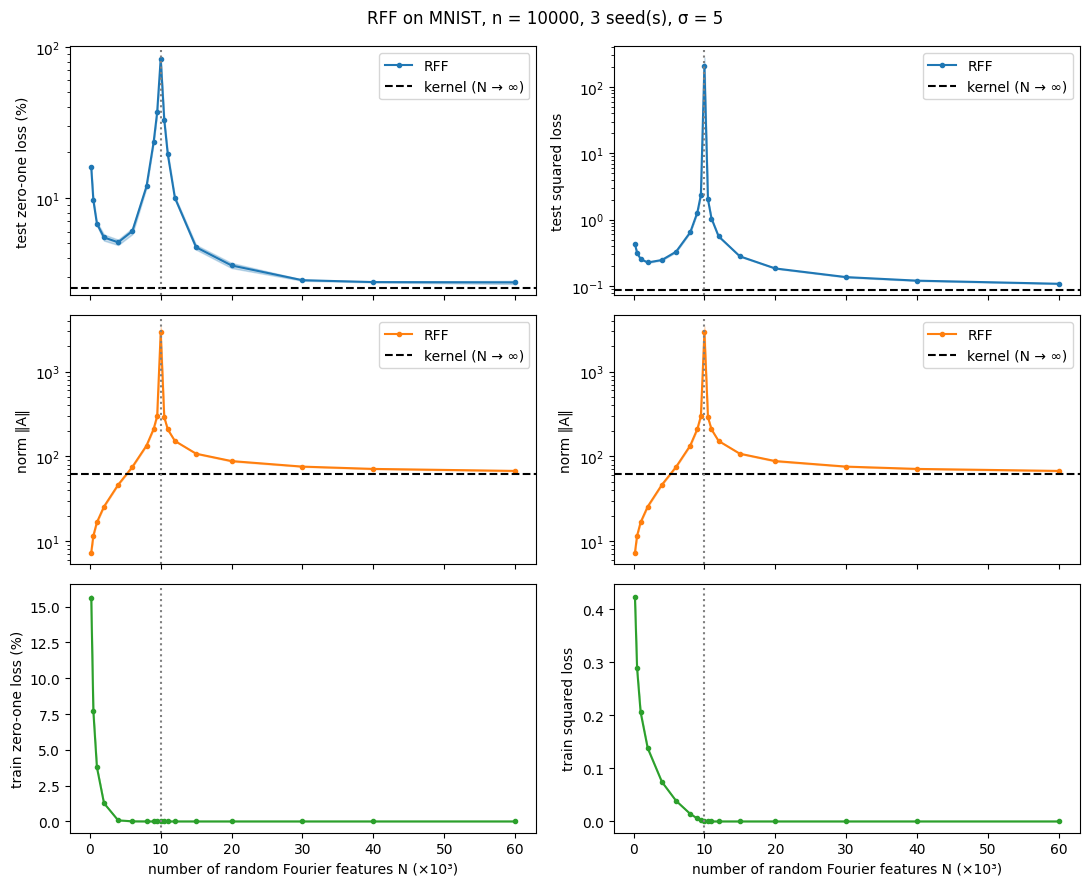

In [24]:
def band(ax, x, g, col, color, label=None):
    m, s = g[col].mean(), g[col].std().fillna(0)
    ax.plot(x, m, "o-", ms=3, color=color, label=label)
    ax.fill_between(x, m - s, m + s, color=color, alpha=0.25)

g = df.groupby("N")
x = np.array(sorted(df.N.unique())) / 1000
fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharex=True)
for j, (test_col, train_col, ylab) in enumerate([("test_err", "train_err", "zero-one loss (%)"),
                                                  ("test_mse", "train_mse", "squared loss")]):
    ax = axes[0, j]; band(ax, x, g, test_col, "C0", "RFF"); ax.set_yscale("log")
    ax.axhline(ker[test_col].mean(), color="k", ls="--", label="kernel (N → ∞)")
    ax.set_ylabel(f"test {ylab}"); ax.legend()
    ax = axes[1, j]; band(ax, x, g, "norm", "C1", "RFF"); ax.set_yscale("log")
    ax.axhline(ker["norm"].mean(), color="k", ls="--", label="kernel (N → ∞)")
    ax.set_ylabel("norm ‖A‖"); ax.legend()
    ax = axes[2, j]; band(ax, x, g, train_col, "C2", "RFF")
    ax.set_ylabel(f"train {ylab}"); ax.set_xlabel("number of random Fourier features N (×10³)")
    for ax in axes[:, j]:
        ax.axvline(N_TRAIN / 1000, color="gray", ls=":")
fig.suptitle(f"RFF on MNIST, n = {N_TRAIN}, {df.seed.nunique()} seed(s), σ = {SIGMA:g}")
fig.tight_layout()
for ext in ["pdf", "png"]:
    fig.savefig(f"{DRIVE_DIR}/figures/rff_mnist_{TAG}.{ext}", dpi=150)
plt.show()